# Heart ultrasound models

CAMUS: official 400/50/50 patient train/validation/test split. Heart segmentation classes: background, LV cavity, myocardium, left atrium. The final cell also trains an ejection-fraction regression baseline using four selected ED/ES phase/view images.

Models are selected using validation data; held-out test results appear only after training finishes. EF errors are percentage points, not classification accuracy.

**Scope:** anatomy contours, image-plane areas, and EF research estimates. No blood-pressure, oxygen-saturation, heart-rate or clot prediction; no astronaut or clinical validation. EF requires correct two-/four-chamber views and ED/ES selection.

CAMUS is restricted to noncommercial scientific research under CC BY-NC-SA 4.0. Cite Leclerc et al., IEEE TMI 2019, doi:10.1109/TMI.2019.2900516. [Official dataset](https://www.creatis.insa-lyon.fr/Challenge/camus/).

Run all on a GPU runtime. Save the final results ZIP before the runtime expires.

In [1]:
%pip -q install nibabel==5.3.2 pillow==11.1.0

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.32.3 which is incompatible.
google-adk 2.7.1 requires requests<3,>=2.32.4, but you have requests 2.32.3 which is incompatible.


## Self-contained pipeline
No external training repository or private Drive dataset is required.

In [2]:
"""Research baseline: patient-disjoint ultrasound segmentation, no clinical claims."""
import os, json, random, hashlib, re
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import requests
import numpy as np
import nibabel as nib
from PIL import Image
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

SEED=42
SIZE=192
ROOT=Path(os.environ.get('ULTRASOUND_ROOT','/content/ultrasound'))
ROOT.mkdir(parents=True,exist_ok=True)
API='https://humanheart-project.creatis.insa-lyon.fr/database/api/v1/'
REV='318d0e04578419d2976a093f9873f14b782f253d'
HF=f'https://huggingface.co/datasets/MedOtter/SegThy/resolve/{REV}/'

def get(url):
    r=requests.get(url,timeout=120); r.raise_for_status(); return r

def download(url,path,sha=None):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    if not path.exists():
        tmp=path.with_suffix(path.suffix+'.part')
        with requests.get(url,stream=True,timeout=120) as r:
            r.raise_for_status()
            with tmp.open('wb') as f:
                for chunk in r.iter_content(1024*1024): f.write(chunk)
        tmp.replace(path)
    digest=hashlib.sha256(path.read_bytes()).hexdigest()
    if sha and digest!=sha: raise ValueError(f'Checksum mismatch: {path}')
    return str(path)

def prepare_heart():
    split={}
    items=get(API+'item?folderId=66e27d12961576b1bad4e4e1&limit=100').json()
    for item in items:
        if item['name'].startswith('subgroup_'):
            name={'training':'train','validation':'val','testing':'test'}[item['name'][9:-4]]
            split[name]=re.findall(r'patient\d+',get(API+'item/'+item['_id']+'/download').text)
    assert sorted(map(len,split.values()))==[50,50,400],split
    folders=get(API+'folder?parentType=folder&parentId=63fde55f73e9f004868fb7ac&limit=1000').json()
    def patient(folder):
        pid=folder['name']; rows=[]
        items=get(API+'item?folderId='+folder['_id']+'&limit=100').json()
        byname={x['name']:x for x in items}
        for view in ['2CH','4CH']:
            for phase in ['ED','ES']:
                stem=f'{pid}_{view}_{phase}'
                paths=[]
                for name in [stem+'.nii.gz',stem+'_gt.nii.gz']:
                    item=byname[name]
                    paths.append(download(API+'item/'+item['_id']+'/download',ROOT/'heart'/'raw'/pid/name))
                rows.append(dict(subject=pid,case=stem,image=paths[0],mask=paths[1],slice=None))
        return rows
    rows=[]
    with ThreadPoolExecutor(max_workers=6) as pool:
        for i,r in enumerate(pool.map(patient,folders)):
            rows.extend(r)
            if i%25==0: print('Downloaded heart patients:',i+1,flush=True)
    return rows,split

def prepare_jugular():
    metadata=[json.loads(x) for x in get(HF+'us_train.jsonl').text.splitlines() if x]
    rows=[]
    for r in metadata:
        if r['annotation_gap']: continue
        paths=[download(HF+r[k],ROOT/'jugular'/'raw'/r[k],r[k+'_sha256']) for k in ['image','mask']]
        rows.append(dict(subject=r['subject_id'],case=r['case_id'],image=paths[0],mask=paths[1],slice=None))
    subjects=sorted({r['subject'] for r in rows});random.Random(SEED).shuffle(subjects)
    assert len(subjects)==16
    split=dict(train=subjects[:10],val=subjects[10:13],test=subjects[13:])
    return rows,split

def preprocess(task,rows,split):
    groups=[set(v) for v in split.values()]
    assert all(not a&b for i,a in enumerate(groups) for b in groups[i+1:])
    assert set.union(*groups)=={r['subject'] for r in rows}
    out=ROOT/task;out.mkdir(exist_ok=True)
    (out/'split.json').write_text(json.dumps(split,indent=2))
    result=[]
    for r in rows:
        ni,nm=nib.load(r['image']),nib.load(r['mask'])
        assert ni.shape==nm.shape and np.allclose(ni.affine,nm.affine),r['case']
        x=np.asarray(ni.dataobj);y=np.asarray(nm.dataobj)
        assert np.isfinite(x).all() and np.isfinite(y).all()
        assert set(np.unique(y)).issubset(set(range(4 if task=='heart' else 6)))
        if task=='heart':
            x,y=x.squeeze(),y.squeeze();assert x.ndim==2
            slices=[(0,x,y)]
        else:
            assert x.ndim==3 and np.isin(y,[3,5]).any(),r['case']
            # Uniform fixed stride includes background; no label-based test selection.
            slices=((z,x[:,:,z],np.isin(y[:,:,z],[3,5]).astype('uint8')) for z in range(0,x.shape[2],8))
        for z,a,b in slices:
            a=a.astype('float32'); lo,hi=np.percentile(a,[1,99])
            a=np.clip((a-lo)/max(float(hi-lo),1e-6),0,1)
            area=float(np.prod(ni.header.get_zooms()[:2])*a.size/(SIZE*SIZE))
            a=np.asarray(Image.fromarray(a).resize((SIZE,SIZE),Image.Resampling.BILINEAR))
            b=np.asarray(Image.fromarray(b.astype('uint8')).resize((SIZE,SIZE),Image.Resampling.NEAREST))
            p=out/'processed'/f"{r['case']}_{z}.npz";p.parent.mkdir(exist_ok=True)
            np.savez_compressed(p,image=a,mask=b)
            result.append(dict(subject=r['subject'],case=r['case'],slice=z,path=str(p),pixel_area_mm2=area,
                               split=next(k for k,v in split.items() if r['subject'] in v)))
    (out/'manifest.json').write_text(json.dumps(result,indent=2))
    return result

class Scans(Dataset):
    def __init__(self,rows): self.rows=rows
    def __len__(self): return len(self.rows)
    def __getitem__(self,i):
        with np.load(self.rows[i]['path']) as d:
            return torch.from_numpy(d['image'].copy())[None],torch.from_numpy(d['mask'].astype('int64')),i

def block(a,b):
    return nn.Sequential(nn.Conv2d(a,b,3,padding=1),nn.GroupNorm(4,b),nn.ReLU(),nn.Conv2d(b,b,3,padding=1),nn.GroupNorm(4,b),nn.ReLU())

class UNet(nn.Module):
    def __init__(self,n):
        super().__init__(); self.a=block(1,16);self.b=block(16,32);self.c=block(32,64)
        self.d=block(96,32);self.e=block(48,16);self.head=nn.Conv2d(16,n,1)
    def forward(self,x):
        a=self.a(x);b=self.b(nn.functional.max_pool2d(a,2));c=self.c(nn.functional.max_pool2d(b,2))
        d=self.d(torch.cat([nn.functional.interpolate(c,size=b.shape[-2:],mode='bilinear',align_corners=False),b],1))
        return self.head(self.e(torch.cat([nn.functional.interpolate(d,size=a.shape[-2:],mode='bilinear',align_corners=False),a],1)))

def loss_fn(logits,y,n):
    p=logits.softmax(1);t=nn.functional.one_hot(y,n).permute(0,3,1,2).float()
    dice=(2*(p*t).sum((0,2,3))+1e-5)/(p.sum((0,2,3))+t.sum((0,2,3))+1e-5)
    return nn.functional.cross_entropy(logits,y)+1-dice[1:].mean()

@torch.no_grad()
def evaluate(model,loader,device,n):
    model.eval();stats={};areas=[]
    for x,y,indices in loader:
        pred=model(x.to(device)).argmax(1).cpu().numpy();y=y.numpy()
        for p,t,i in zip(pred,y,indices):
            r=loader.dataset.rows[int(i)];s=stats.setdefault(r['subject'],np.zeros((n-1,3)))
            for k in range(1,n):
                a,b=p==k,t==k;s[k-1]+=[(a&b).sum(),a.sum(),b.sum()]
                areas.append(dict(subject=r['subject'],case=r['case'],slice=r['slice'],label=k,
                    predicted_area_mm2=float(a.sum()*r['pixel_area_mm2']),reference_area_mm2=float(b.sum()*r['pixel_area_mm2'])))
    records=[]
    for subject,s in stats.items():
        for k,(inter,p,t) in enumerate(s,1):
            records.append(dict(subject=subject,label=k,dice=float(2*inter/(p+t)) if p+t else None,
                iou=float(inter/(p+t-inter)) if p+t-inter else None))
    values=[r['dice'] for r in records if r['dice'] is not None]
    return float(np.mean(values)),records,areas

def train(task,manifest,epochs=25):
    random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
    n=4 if task=='heart' else 2; device='cuda' if torch.cuda.is_available() else 'cpu'
    print('Device:',device,flush=True)
    loaders={k:DataLoader(Scans([r for r in manifest if r['split']==k]),batch_size=12,shuffle=k=='train',num_workers=0) for k in ['train','val','test']}
    assert all(len(v.dataset)>0 for v in loaders.values())
    model=UNet(n).to(device);opt=torch.optim.AdamW(model.parameters(),lr=3e-4)
    out=ROOT/task;best=-1;history=[]
    for epoch in range(epochs):
        model.train();total=0
        for x,y,_ in loaders['train']:
            x,y=x.to(device),y.to(device);opt.zero_grad();loss=loss_fn(model(x),y,n);loss.backward();opt.step();total+=loss.item()*len(x)
        score,_,_=evaluate(model,loaders['val'],device,n)
        history.append(dict(epoch=epoch+1,train_loss=total/len(loaders['train'].dataset),validation_dice=score));print(history[-1],flush=True)
        if score>best:
            best=score;torch.save(dict(state_dict=model.state_dict(),classes=n,size=SIZE,task=task,seed=SEED,epoch=epoch+1),out/'best.pt')
        (out/'history.json').write_text(json.dumps(history,indent=2))
    model.load_state_dict(torch.load(out/'best.pt',map_location=device,weights_only=True)['state_dict'])
    score,records,areas=evaluate(model,loaders['test'],device,n)
    # Patient bootstrap, not slices as independent observations.
    subjects=sorted({r['subject'] for r in records})
    vals=np.array([np.mean([r['dice'] for r in records if r['subject']==s and r['dice'] is not None]) for s in subjects])
    rng=np.random.default_rng(SEED);ci=np.percentile([rng.choice(vals,len(vals),replace=True).mean() for _ in range(2000)],[2.5,97.5])
    report=dict(test_mean_patient_dice=score,bootstrap_95_percent_ci=ci.tolist(),test_subjects=len(subjects),per_subject=records,
                limitation='Earth data only; no astronaut, vital-sign or clot validation. Jugular test cohort is very small.')
    (out/'test_metrics.json').write_text(json.dumps(report,indent=2));(out/'test_areas.json').write_text(json.dumps(areas,indent=2))
    print(json.dumps(report,indent=2));return model

@torch.no_grad()
def predict(image,checkpoint):
    """Input: single 2D grayscale array in the same orientation as training NIfTI."""
    c=torch.load(checkpoint,map_location='cpu',weights_only=True);model=UNet(c['classes']);model.load_state_dict(c['state_dict']);model.eval()
    a=np.asarray(image,dtype='float32');assert a.ndim==2 and np.isfinite(a).all()
    lo,hi=np.percentile(a,[1,99]);a=np.clip((a-lo)/max(float(hi-lo),1e-6),0,1)
    x=torch.from_numpy(np.asarray(Image.fromarray(a).resize((SIZE,SIZE),Image.Resampling.BILINEAR)).copy())[None,None]
    p=model(x).argmax(1)[0].numpy().astype('uint8')
    return np.asarray(Image.fromarray(p).resize((image.shape[1],image.shape[0]),Image.Resampling.NEAREST))


In [3]:
TASK='heart'
EPOCHS=25
rows,split=prepare_heart()
print({k:len(v) for k,v in split.items()})
manifest=preprocess(TASK,rows,split)
print('Images/slices:',{k:sum(r['split']==k for r in manifest) for k in split})

Downloaded heart patients: 1
Downloaded heart patients: 26
Downloaded heart patients: 51
Downloaded heart patients: 76
Downloaded heart patients: 101
Downloaded heart patients: 126
Downloaded heart patients: 151
Downloaded heart patients: 176
Downloaded heart patients: 201
Downloaded heart patients: 226
Downloaded heart patients: 251
Downloaded heart patients: 276
Downloaded heart patients: 301
Downloaded heart patients: 326
Downloaded heart patients: 351
Downloaded heart patients: 376
Downloaded heart patients: 401
Downloaded heart patients: 426
Downloaded heart patients: 451
Downloaded heart patients: 476
{'test': 50, 'train': 400, 'val': 50}
Images/slices: {'test': 200, 'train': 1600, 'val': 200}


## Training and held-out evaluation
Dice/IoU are accumulated by patient before averaging. Confidence intervals resample patients, not adjacent slices. Three test subjects for jugular provide very uncertain evidence. Do not tune settings on the test results.

In [4]:
model=train(TASK,manifest,epochs=EPOCHS)

Device: cuda
{'epoch': 1, 'train_loss': 1.7070972883701325, 'validation_dice': 0.5134812192040663}
{'epoch': 2, 'train_loss': 1.3213233309984207, 'validation_dice': 0.6617006630547195}
{'epoch': 3, 'train_loss': 1.0106720267236233, 'validation_dice': 0.7244958181713842}
{'epoch': 4, 'train_loss': 0.7870561389625073, 'validation_dice': 0.7622456880650801}
{'epoch': 5, 'train_loss': 0.6588550962507724, 'validation_dice': 0.7863079107426272}
{'epoch': 6, 'train_loss': 0.5668035048246384, 'validation_dice': 0.7975711474512001}
{'epoch': 7, 'train_loss': 0.5020812210440636, 'validation_dice': 0.812393274403833}
{'epoch': 8, 'train_loss': 0.47312462493777274, 'validation_dice': 0.8165766155854977}
{'epoch': 9, 'train_loss': 0.44538974061608316, 'validation_dice': 0.8190664696406427}
{'epoch': 10, 'train_loss': 0.40992088586091996, 'validation_dice': 0.8356882217095699}
{'epoch': 11, 'train_loss': 0.3987928611040115, 'validation_dice': 0.8066289338571346}
{'epoch': 12, 'train_loss': 0.3838992

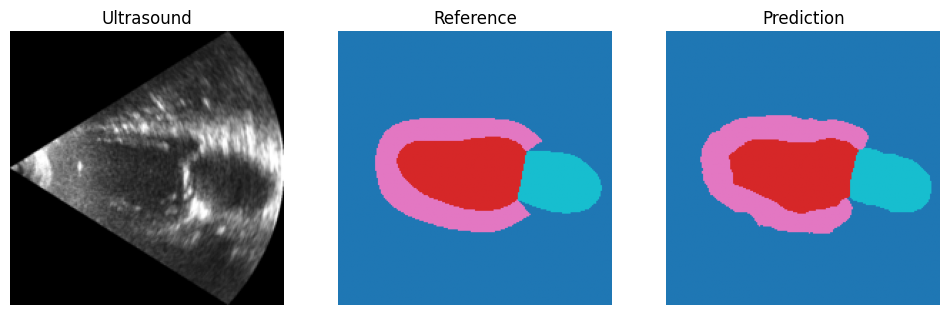

Label 1 patient-mean area MAE (mm2): 237.6140995271504
Label 2 patient-mean area MAE (mm2): 297.54997647672894
Label 3 patient-mean area MAE (mm2): 219.44900912001728


In [5]:
import matplotlib.pyplot as plt
example=next(r for r in manifest if r['split']=='test')
with np.load(example['path']) as d:
    im,truth=d['image'],d['mask']
model.eval()
with torch.no_grad():
    pred=model(torch.from_numpy(im.copy())[None,None].to(next(model.parameters()).device)).argmax(1)[0].cpu().numpy()
fig,axes=plt.subplots(1,3,figsize=(12,4))
for ax,arr,title in zip(axes,[im,truth,pred],['Ultrasound','Reference','Prediction']):
    ax.imshow(arr,cmap='gray' if title=='Ultrasound' else 'tab10');ax.set_title(title);ax.axis('off')
plt.show()
areas=json.loads((ROOT/TASK/'test_areas.json').read_text())
for label in sorted({r['label'] for r in areas}):
    subjects=sorted({r['subject'] for r in areas})
    errors=[np.mean([abs(r['predicted_area_mm2']-r['reference_area_mm2']) for r in areas if r['label']==label and r['subject']==s]) for s in subjects]
    print('Label',label,'patient-mean area MAE (mm2):',float(np.mean(errors)))

## Download trained model and audit files
Save this ZIP before the runtime expires. It contains the checkpoint, exact patient split, manifest, metrics, history and prediction measurements. Raw datasets remain subject to their original licenses.

In [6]:
import zipfile
from google.colab import files
archive=ROOT/f'{TASK}_results.zip'
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
    for name in ['best.pt','split.json','manifest.json','history.json','test_metrics.json','test_areas.json']:
        z.write(ROOT/TASK/name,name)
files.download(str(archive))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
# EF regression: four selected ED/ES frames; research only.
import threading
_local=threading.local()
def ef_request(url):
    if not hasattr(_local,'session'): _local.session=requests.Session()
    r=_local.session.get(url,timeout=120);r.raise_for_status();return r

def fetch_ef_labels():
    folders=ef_request(API+'folder?parentType=folder&parentId=63fde55f73e9f004868fb7ac&limit=1000').json()
    def one(f):
        p=ROOT/'heart'/'raw'/f['name']/'Info_2CH.cfg'
        if not p.exists():
            items=ef_request(API+'item?folderId='+f['_id']+'&limit=100').json()
            item=next(x for x in items if x['name']=='Info_2CH.cfg')
            p.write_text(ef_request(API+'item/'+item['_id']+'/download').text)
        cfg=dict(line.split(':',1) for line in p.read_text().splitlines() if ':' in line)
        value=float(cfg['EF']);assert 0<=value<=100
        return f['name'],value
    with ThreadPoolExecutor(max_workers=8) as pool:labels=dict(pool.map(one,folders))
    (ROOT/'heart'/'ef_labels.json').write_text(json.dumps(labels,indent=2));return labels

class EFCases(Dataset):
    def __init__(self,manifest,labels,split):
        self.subjects=sorted({r['subject'] for r in manifest if r['split']==split})
        self.data=[];self.labels=labels
        for subject in self.subjects:
            bycase={r['case']:r for r in manifest if r['subject']==subject}
            images=[]
            for view in ['2CH','4CH']:
                for phase in ['ED','ES']:
                    with np.load(bycase[f'{subject}_{view}_{phase}']['path']) as d:images.append(d['image'].copy())
            self.data.append(np.stack(images))
    def __len__(self):return len(self.subjects)
    def __getitem__(self,i):return torch.from_numpy(self.data[i]),torch.tensor(self.labels[self.subjects[i]]/100,dtype=torch.float32),i

class EFNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net=nn.Sequential(nn.Conv2d(4,16,5,stride=2,padding=2),nn.ReLU(),nn.Conv2d(16,32,3,stride=2,padding=1),nn.ReLU(),nn.Conv2d(32,64,3,stride=2,padding=1),nn.ReLU(),nn.AdaptiveAvgPool2d((4,4)),nn.Flatten(),nn.Linear(1024,64),nn.ReLU(),nn.Linear(64,1),nn.Sigmoid())
    def forward(self,x):return self.net(x).squeeze(1)

@torch.no_grad()
def ef_predictions(model,loader,device):
    model.eval();rows=[]
    for x,y,indices in loader:
        pred=model(x.to(device)).cpu().numpy()*100
        for p,t,i in zip(pred,y.numpy()*100,indices):
            rows.append(dict(subject=loader.dataset.subjects[int(i)],reference_ef=float(t),predicted_ef=float(p)))
    return rows

def train_ef(manifest,epochs=40):
    labels=fetch_ef_labels();torch.manual_seed(SEED);np.random.seed(SEED);random.seed(SEED)
    device='cuda' if torch.cuda.is_available() else 'cpu';model=EFNet().to(device)
    loaders={k:DataLoader(EFCases(manifest,labels,k),batch_size=16,shuffle=k=='train') for k in ['train','val','test']}
    opt=torch.optim.AdamW(model.parameters(),lr=3e-4);best=float('inf');history=[];out=ROOT/'heart'
    for epoch in range(epochs):
        model.train()
        for x,y,_ in loaders['train']:
            opt.zero_grad();loss=nn.functional.mse_loss(model(x.to(device)),y.to(device));loss.backward();opt.step()
        rows=ef_predictions(model,loaders['val'],device);mae=np.mean([abs(r['predicted_ef']-r['reference_ef']) for r in rows])
        history.append(dict(epoch=epoch+1,validation_mae_percentage_points=float(mae)))
        if mae<best:
            best=mae;torch.save(dict(state_dict=model.state_dict(),epoch=epoch+1,input_order=['2CH_ED','2CH_ES','4CH_ED','4CH_ES']),out/'ef_best.pt')
        if (epoch+1)%5==0:print(history[-1],flush=True)
    model.load_state_dict(torch.load(out/'ef_best.pt',map_location=device,weights_only=True)['state_dict'])
    rows=ef_predictions(model,loaders['test'],device)
    errors=np.array([r['predicted_ef']-r['reference_ef'] for r in rows])
    mean=np.mean([labels[s] for s in loaders['train'].dataset.subjects]);rng=np.random.default_rng(SEED)
    report=dict(test_subjects=len(rows),mae_percentage_points=float(np.abs(errors).mean()),rmse_percentage_points=float(np.sqrt((errors**2).mean())),train_mean_baseline_mae=float(np.mean([abs(mean-r['reference_ef']) for r in rows])),bootstrap_mae_95_percent_ci=np.percentile([rng.choice(np.abs(errors),len(errors),replace=True).mean() for _ in range(2000)],[2.5,97.5]).tolist(),predictions=rows,limitation='Requires selected ED/ES frames in both views. No automatic phase/view detection or astronaut validation. Research baseline only.')
    (out/'ef_test_metrics.json').write_text(json.dumps(report,indent=2));(out/'ef_history.json').write_text(json.dumps(history,indent=2))
    print(json.dumps({k:v for k,v in report.items() if k!='predictions'},indent=2));return model

ef_model=train_ef(manifest)
with zipfile.ZipFile(ROOT/'heart_results_complete.zip','w',zipfile.ZIP_DEFLATED) as z:
    for name in ['best.pt','split.json','manifest.json','history.json','test_metrics.json','test_areas.json','ef_best.pt','ef_labels.json','ef_history.json','ef_test_metrics.json']:
        z.write(ROOT/'heart'/name,name)
files.download(str(ROOT/'heart_results_complete.zip'))


{'epoch': 5, 'validation_mae_percentage_points': 10.09852767944336}
{'epoch': 10, 'validation_mae_percentage_points': 10.096206436157226}
{'epoch': 15, 'validation_mae_percentage_points': 10.055850143432616}
{'epoch': 20, 'validation_mae_percentage_points': 9.092738037109376}
{'epoch': 25, 'validation_mae_percentage_points': 7.198957023620605}
{'epoch': 30, 'validation_mae_percentage_points': 6.609236679077148}
{'epoch': 35, 'validation_mae_percentage_points': 6.33129322052002}
{'epoch': 40, 'validation_mae_percentage_points': 6.445280342102051}
{
  "test_subjects": 50,
  "mae_percentage_points": 8.048834838867187,
  "rmse_percentage_points": 10.382876516113086,
  "train_mean_baseline_mae": 9.364399923706054,
  "bootstrap_mae_95_percent_ci": [
    6.335002861976624,
    10.00153583908081
  ],
  "limitation": "Requires selected ED/ES frames in both views. No automatic phase/view detection or astronaut validation. Research baseline only."
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>